This notebooks is for detecting cell line outliers, i.e. targets that were specific in a cell line.

In [1]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
import PyComplexHeatmap as pch
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
# from utils import ...

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

TEMPDIR = Path(config['TEMPDIR'])

In [3]:
# Get counts
counts = pd.read_csv(TEMPDIR / 'SYM101_counts.csv', index_col=0)

Targets that are differential hits between cell lines.

In [4]:
tab = pd.read_csv('../results/merged/gene_results_perline.csv', index_col=0, header=[0,1])

In [5]:
mageck_std = tab.loc[:, (slice(None), 'MAGeCK_score')].std(axis=1)
bagel2_std = tab.loc[:, (slice(None), 'Bagel2_Bayesfactor')].std(axis=1)
gscreend_std = tab.loc[:, (slice(None), 'Gscreend_FDR')].std(axis=1)
stab = pd.concat([mageck_std, bagel2_std, gscreend_std], axis=1, keys=['MAGeCK', 'Bagel2', 'Gscreend'])

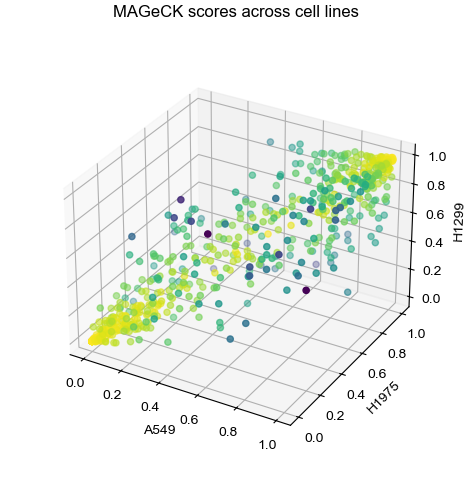

In [6]:
# make this an interactive 3d scatterplot instead
# sns.scatterplot(data=tab, x=('A549', 'MAGeCK_score'), y=('H1975', 'MAGeCK_score'), hue=('H1299', 'MAGeCK_score'))
fig, ax = pl.subplots(subplot_kw={'projection': '3d'}, figsize=(8,6))

# calculate distance from diagonal
dist = np.sqrt((tab.loc[:, ('A549', 'MAGeCK_score')] - tab.loc[:, ('H1975', 'MAGeCK_score')])**2 + (tab.loc[:, ('H1975', 'MAGeCK_score')] - tab.loc[:, ('H1299', 'MAGeCK_score')])**2)

ax.scatter(tab.loc[:, ('A549', 'MAGeCK_score')], tab.loc[:, ('H1975', 'MAGeCK_score')], tab.loc[:, ('H1299', 'MAGeCK_score')], c=dist, cmap='viridis_r', s=20)
ax.set_xlabel('A549')
ax.set_ylabel('H1975')
ax.set_zlabel('H1299')
ax.set_title('MAGeCK scores across cell lines')
ax.set_box_aspect(aspect=None, zoom=0.85)

pl.show()

<Axes: xlabel='None-None'>

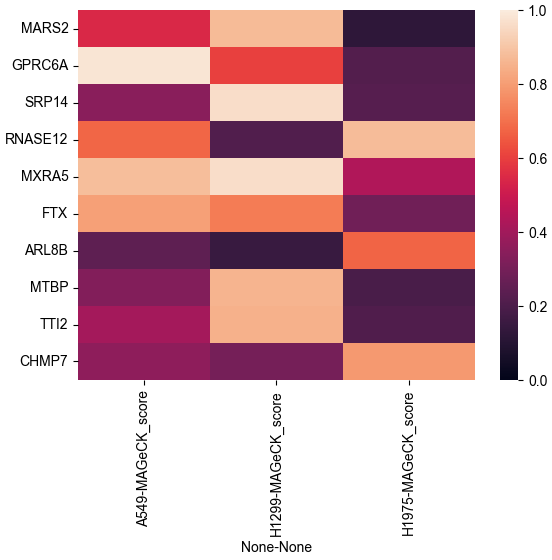

In [6]:
tops = pd.Series(dist).sort_values(ascending=False).head(10)
sns.heatmap(tab.loc[tops.index, (slice(None), 'MAGeCK_score')], vmin=0, vmax=1)

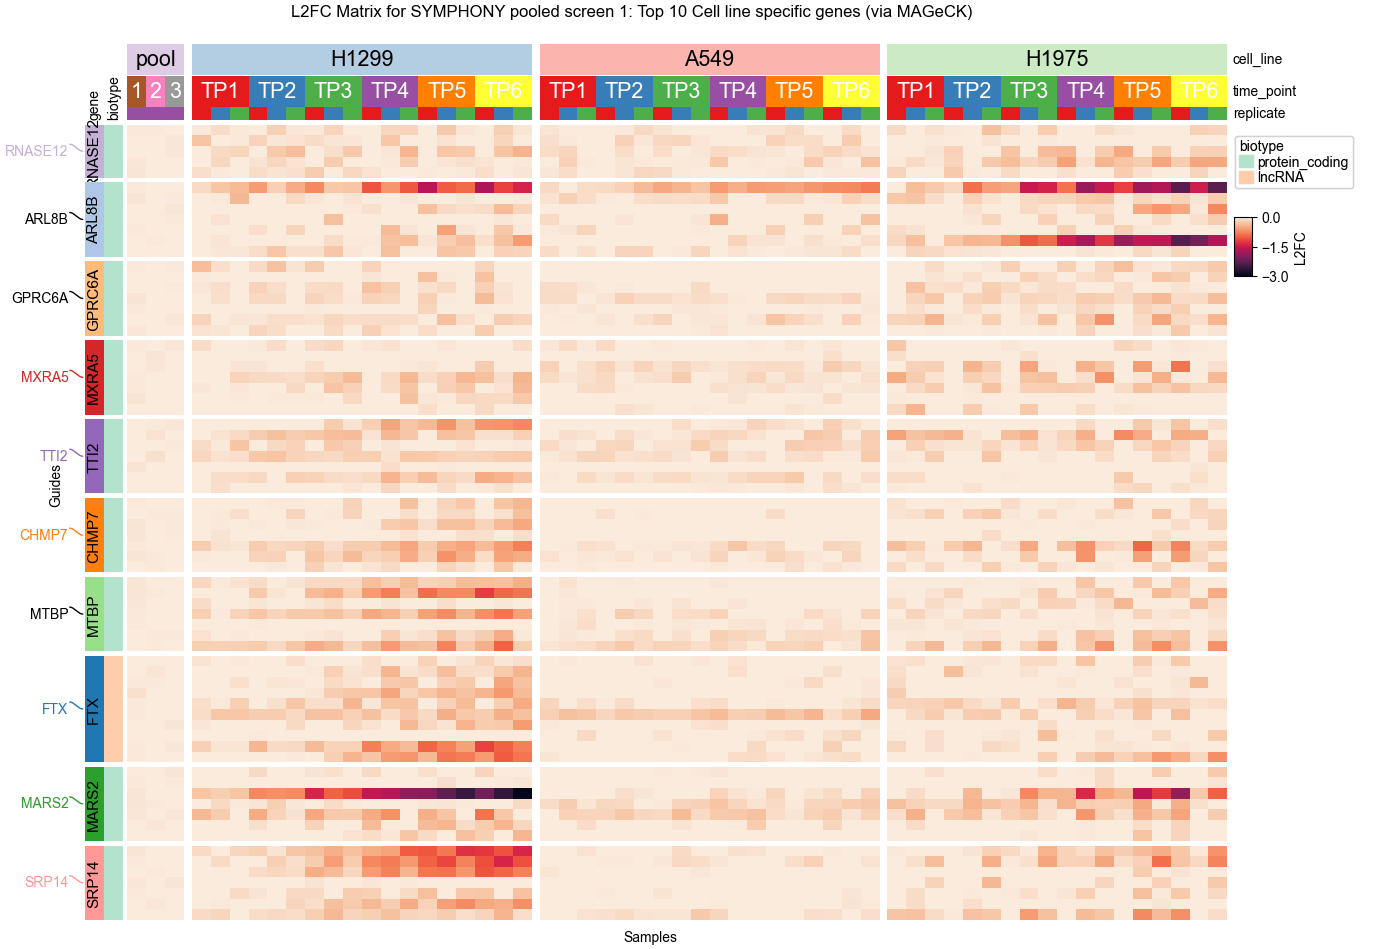

In [7]:
# visualize in heatmap
df = pd.read_csv(TEMPDIR / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

# First I normalize for seq-depth by bringing all NT guides to the same count
target = df.loc[controls, sample_names_wo_pools].mean().mean()  # mean of NTs in control
ist = df.loc[controls, sample_names].mean()  # mean of NTs in all
norm_factor = target / ist  # make all NT mean counts equal to those in control
ndf = df.loc[:, sample_names] * norm_factor  # normalize

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T  # normalize to control (pools)
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

import PyComplexHeatmap as pch
df['mean_l2fc'] = l2fc.mean(axis=1)

df = df[df.Gene.isin(tops.index)]
l2fc = l2fc.loc[df.index]

biotype = df.sort_values(['transcript_biotype', 'mean_l2fc']).transcript_biotype
biotype = biotype[~biotype.isin(['protein_coding_CDS_not_defined', 'retained_intron'])]

cell_line_dict_ = {f'0{x}': y for x, y in cell_line_dict.items()}
cell_line = pd.Series({x: x.split('-')[1] for x in sample_names}).replace(cell_line_dict_)
replicate = pd.Series({x: x.split('-')[2] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

# select and reorder
data = l2fc.loc[:, col_order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=7, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df.Gene, merge=True, cmap='tab20'),
    gene=pch.anno_simple(df.Gene, legend=False, height=5, add_text=True, cmap='tab20'),
    biotype=pch.anno_simple(biotype, legend=True, height=5, add_text=False, cmap='Pastel2'),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(15, 10))
cm = pch.ClusterMapPlotter(
    data=data, 
    left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    col_split=cell_line.loc[col_order],
    col_split_gap=2, row_split_gap=1,
    row_split=df.Gene,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=-3, vmax=0,
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Guides', legend_hpad=0,
    verbose=0
)
pl.suptitle('L2FC Matrix for SYMPHONY pooled screen 1: Top 10 Cell line specific genes (via MAGeCK)', y=0.92)
pl.savefig('../results/cell_line_specificity/count_matrix_l2fc_heatmap_simple.png', dpi=300)
pl.savefig('../results/cell_line_specificity/count_matrix_l2fc_heatmap_simple.pdf', dpi=300)
pl.show()

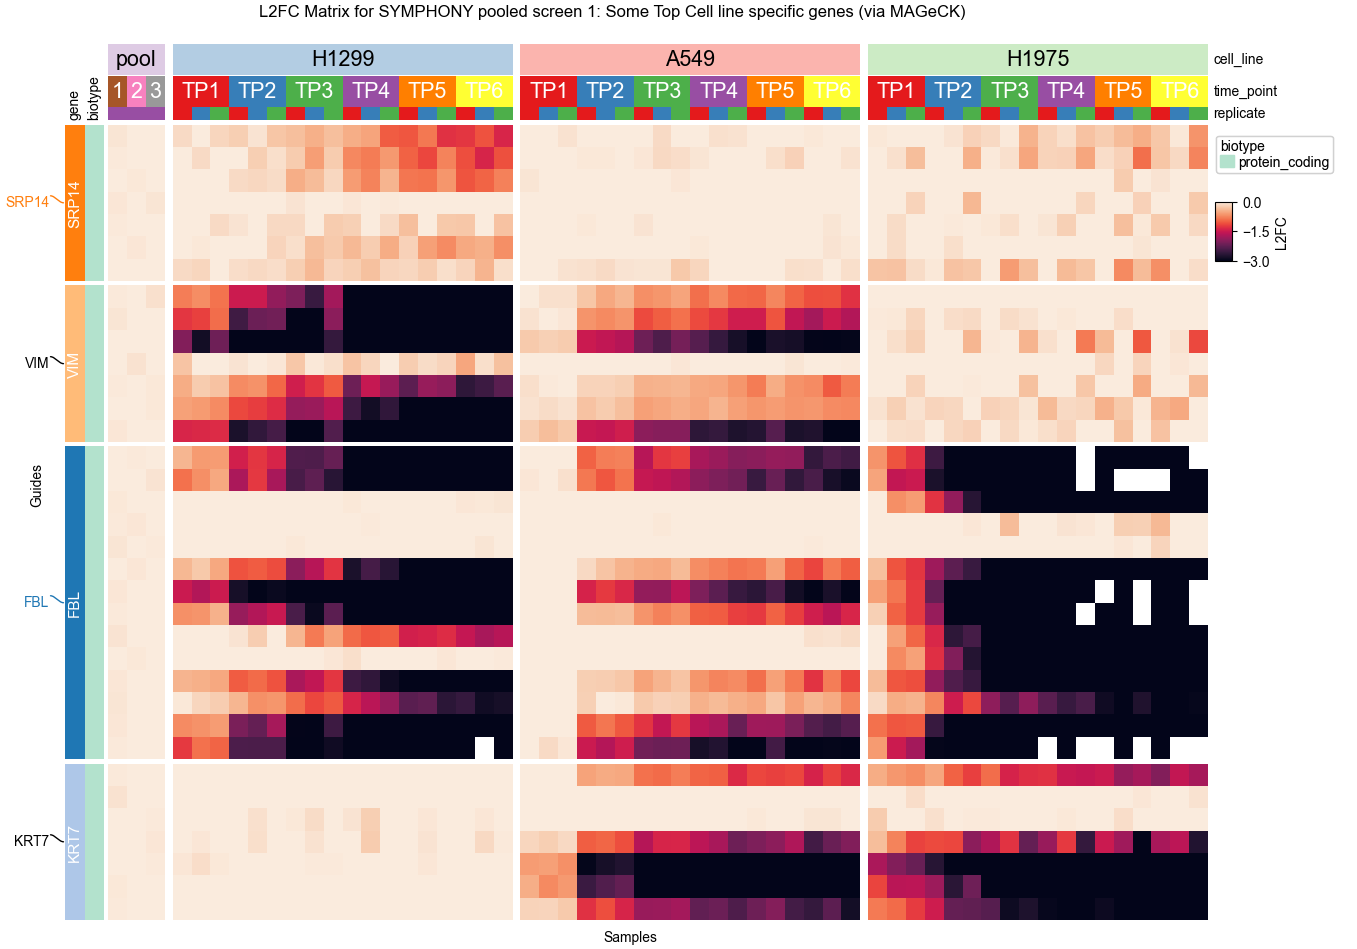

In [8]:
# CUSTOM GENE SELECTION
genes = ['VIM', 'KRT7', 'FBL', 'SRP14']
# genes = ['ARL8B', 'MTBP', 'MARS2', 'SRP14', 'RPS5', 'FBL', 'KRT8', 'VIM', 'KRT7']

# visualize in heatmap
df = pd.read_csv(TEMPDIR / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

# First I normalize for seq-depth by bringing all NT guides to the same count
target = df.loc[controls, sample_names_wo_pools].mean().mean()  # mean of NTs in control
ist = df.loc[controls, sample_names].mean()  # mean of NTs in all
norm_factor = target / ist  # make all NT mean counts equal to those in control
ndf = df.loc[:, sample_names] * norm_factor  # normalize

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T  # normalize to control (pools)
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

import PyComplexHeatmap as pch
df['mean_l2fc'] = l2fc.mean(axis=1)

df = df[df.Gene.isin(genes)]
l2fc = l2fc.loc[df.index]

biotype = df.sort_values(['transcript_biotype', 'mean_l2fc']).transcript_biotype
biotype = biotype[~biotype.isin(['protein_coding_CDS_not_defined', 'retained_intron'])]

cell_line_dict_ = {f'0{x}': y for x, y in cell_line_dict.items()}
cell_line = pd.Series({x: x.split('-')[1] for x in sample_names}).replace(cell_line_dict_)
replicate = pd.Series({x: x.split('-')[2] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

# select and reorder
data = l2fc.loc[:, col_order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=7, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df.Gene, merge=True, cmap='tab20'),
    gene=pch.anno_simple(df.Gene, legend=False, height=5, add_text=True, cmap='tab20'),
    biotype=pch.anno_simple(biotype, legend=True, height=5, add_text=False, cmap='Pastel2'),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(15, 10))
cm = pch.ClusterMapPlotter(
    data=data, 
    left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    col_split=cell_line.loc[col_order],
    col_split_gap=2, row_split_gap=1,
    row_split=df.Gene,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=-3, vmax=0,
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Guides', legend_hpad=0,
    verbose=0
)
pl.suptitle('L2FC Matrix for SYMPHONY pooled screen 1: Some Top Cell line specific genes (via MAGeCK)', y=0.92)
pl.savefig('../results/figures/count_matrix_l2fc_heatmap_simple_2.png', dpi=300)
pl.savefig('../results/figures/count_matrix_l2fc_heatmap_simple_2.pdf', dpi=300)
pl.show()

In [9]:
selection="""PPIA_ENST00000355968_613
PPIA_ENST00000355968_657
PPIA_ENST00000355968_39
PPIA_ENST00000355968_49
PPIA_ENST00000355968_561
PPIA_ENST00000355968_533
PPIA_ENST00000355968_609
PPIA_ENST00000451562_489
PPIA_ENST00000451562_424
PPIA_ENST00000451562_42
PPIA_ENST00000451562_41
PPIA_ENST00000451562_51
PPIA_ENST00000451562_412
PPIA_ENST00000451562_148
ELAC2_ENST00000395962_2892
ELAC2_ENST00000395962_2880
ELAC2_ENST00000395962_27
ELAC2_ENST00000395962_25
ELAC2_ENST00000395962_2008
ELAC2_ENST00000395962_1919
ELAC2_ENST00000395962_1696
ELAC2_ENST00000338034_3113
ELAC2_ENST00000338034_3102
ELAC2_ENST00000338034_43
ELAC2_ENST00000338034_229
ELAC2_ENST00000338034_1920
ELAC2_ENST00000338034_976
ELAC2_ENST00000338034_1564
U2AF1_ENST00000291552_837
U2AF1_ENST00000291552_833
U2AF1_ENST00000291552_83
U2AF1_ENST00000291552_444
U2AF1_ENST00000291552_488
U2AF1_ENST00000291552_330
U2AF1_ENST00000291552_440
U2AF1_ENST00000380276_805
U2AF1_ENST00000380276_838
U2AF1_ENST00000380276_56
U2AF1_ENST00000380276_61
U2AF1_ENST00000380276_85
U2AF1_ENST00000380276_418
U2AF1_ENST00000380276_223
SNHG16_ENST00000493536_205
SNHG16_ENST00000493536_264
SNHG16_ENST00000493536_558
SNHG16_ENST00000493536_623
SNHG16_ENST00000493536_1028
SNHG16_ENST00000493536_1030
SNHG16_ENST00000493536_1636
SNHG16_ENST00000493536_1827
SNHG16_ENST00000493536_2093
SNHG16_ENST00000493536_2379
MALAT1_ENST00000534336_190
MALAT1_ENST00000534336_1658
MALAT1_ENST00000534336_2304
MALAT1_ENST00000534336_3033
MALAT1_ENST00000534336_3929
MALAT1_ENST00000534336_4465
MALAT1_ENST00000534336_5350
MALAT1_ENST00000534336_6548
MALAT1_ENST00000534336_7643
MALAT1_ENST00000534336_8426
SNHG1_ENST00000539921_82
SNHG1_ENST00000539921_209
SNHG1_ENST00000539921_216
SNHG1_ENST00000539921_371
SNHG1_ENST00000539921_555
SNHG1_ENST00000539921_597
SNHG1_ENST00000539921_760
SNHG1_ENST00000539921_845
SNHG1_ENST00000539921_937
SNHG1_ENST00000539921_1029
NEAT1_ENST00000501122_884
NEAT1_ENST00000501122_3330
NEAT1_ENST00000501122_4713
NEAT1_ENST00000501122_7534
NEAT1_ENST00000501122_10896
NEAT1_ENST00000501122_12578
NEAT1_ENST00000501122_15048
NEAT1_ENST00000501122_16384
NEAT1_ENST00000501122_20199
NEAT1_ENST00000501122_20605
ZFAS1_ENST00000428008_66
ZFAS1_ENST00000428008_71
ZFAS1_ENST00000428008_133
ZFAS1_ENST00000428008_216
ZFAS1_ENST00000428008_270
ZFAS1_ENST00000428008_328
ZFAS1_ENST00000428008_359
ZFAS1_ENST00000428008_423
ZFAS1_ENST00000428008_501
ZFAS1_ENST00000428008_547
SNHG6_ENST00000520944_41
SNHG6_ENST00000520944_114
SNHG6_ENST00000520944_169
SNHG6_ENST00000520944_201
SNHG6_ENST00000520944_280
SNHG6_ENST00000520944_366
SNHG6_ENST00000520944_398
SNHG6_ENST00000520944_497
SNHG6_ENST00000520944_575
SNHG6_ENST00000520944_635
SNHG6_ENST00000521399_79
SNHG6_ENST00000521399_80
SNHG6_ENST00000521399_120
SNHG6_ENST00000521399_134
SNHG6_ENST00000521399_179
SNHG6_ENST00000521399_180
SNHG6_ENST00000521399_199
SNHG6_ENST00000521399_231
SNHG15_ENST00000580458_27
SNHG15_ENST00000580458_77
SNHG15_ENST00000580458_184
SNHG15_ENST00000580458_229
SNHG15_ENST00000580458_324
SNHG15_ENST00000580458_407
SNHG15_ENST00000580458_476
SNHG15_ENST00000580458_479
SNHG15_ENST00000580458_620
SNHG15_ENST00000580458_706
GAS5_ENST00000448718_47
GAS5_ENST00000448718_49
GAS5_ENST00000448718_196
GAS5_ENST00000448718_217
GAS5_ENST00000448718_264
GAS5_ENST00000448718_267
GAS5_ENST00000448718_340
GAS5_ENST00000448718_436
GAS5_ENST00000448718_524
GAS5_ENST00000448718_554
GAS5_ENST00000450589_35
GAS5_ENST00000450589_75
GAS5_ENST00000450589_224
GAS5_ENST00000450589_245
GAS5_ENST00000450589_250
GAS5_ENST00000450589_334
GAS5_ENST00000450589_376
GAS5_ENST00000450589_407
GAS5_ENST00000450589_503
GAS5_ENST00000450589_621
LINC-PINT_ENST00000418546_130
LINC-PINT_ENST00000418546_153
LINC-PINT_ENST00000418546_240
LINC-PINT_ENST00000418546_279
LINC-PINT_ENST00000418546_311
LINC-PINT_ENST00000418546_349
LINC-PINT_ENST00000418546_400
LINC-PINT_ENST00000418546_440
FENDRR_ENST00000598996_166
FENDRR_ENST00000598996_551
FENDRR_ENST00000598996_727
FENDRR_ENST00000598996_1032
FENDRR_ENST00000598996_1267
FENDRR_ENST00000598996_1288
FENDRR_ENST00000598996_1999
FENDRR_ENST00000598996_2006
FENDRR_ENST00000598996_2346
FENDRR_ENST00000598996_2742
HOTAIR_ENST00000424518_327
HOTAIR_ENST00000424518_402
HOTAIR_ENST00000424518_556
HOTAIR_ENST00000424518_811
HOTAIR_ENST00000424518_1166
HOTAIR_ENST00000424518_1303
HOTAIR_ENST00000424518_1606
HOTAIR_ENST00000424518_1771
HOTAIR_ENST00000424518_2219
HOTAIR_ENST00000424518_2308
TERC_ENST00000602385_24
TERC_ENST00000602385_104
TERC_ENST00000602385_113
TERC_ENST00000602385_115
TERC_ENST00000602385_316
TERC_ENST00000602385_457
TERC_ENST00000602385_472
HOTTIP_ENST00000521028_224
HOTTIP_ENST00000521028_546
HOTTIP_ENST00000521028_1191
HOTTIP_ENST00000521028_1428
HOTTIP_ENST00000521028_1942
HOTTIP_ENST00000521028_2696
HOTTIP_ENST00000521028_3009
HOTTIP_ENST00000521028_3460
HOTTIP_ENST00000521028_3865
HOTTIP_ENST00000521028_4272
RPS16_ENST00000251453_559
RPS16_ENST00000251453_523
RPS16_ENST00000251453_49
RPS16_ENST00000251453_50
RPS16_ENST00000251453_300
RPS16_ENST00000251453_281
RPS16_ENST00000251453_280
FTL_ENST00000331825_764
FTL_ENST00000331825_869
FTL_ENST00000331825_45
FTL_ENST00000331825_58
FTL_ENST00000331825_711
FTL_ENST00000331825_330
FTL_ENST00000331825_554
GAPDH_ENST00000229239_1847
GAPDH_ENST00000229239_1845
GAPDH_ENST00000229239_243
GAPDH_ENST00000229239_568
GAPDH_ENST00000229239_704
GAPDH_ENST00000229239_858
GAPDH_ENST00000229239_746
H2AC17_ENST00000359611_441
H2AC17_ENST00000359611_37
H2AC17_ENST00000359611_36
H2AC17_ENST00000359611_45
H2AC17_ENST00000359611_122
H2AC17_ENST00000359611_420
H2AC17_ENST00000359611_43
EGFR_ENST00000275493_7380
EGFR_ENST00000275493_9428
EGFR_ENST00000275493_144
EGFR_ENST00000275493_148
EGFR_ENST00000275493_451
EGFR_ENST00000275493_317
EGFR_ENST00000275493_2901
MYC_ENST00000377970_1886
MYC_ENST00000377970_1931
MYC_ENST00000377970_385
MYC_ENST00000377970_350
MYC_ENST00000377970_575
MYC_ENST00000377970_629
MYC_ENST00000377970_1722
RAN_ENST00000392367_747
RAN_ENST00000392367_780
RAN_ENST00000392367_36
RAN_ENST00000392367_279
RAN_ENST00000392367_600
RAN_ENST00000392367_505
RAN_ENST00000392367_278
DTX2_ENST00000430490_2341
DTX2_ENST00000430490_2344
DTX2_ENST00000430490_130
DTX2_ENST00000430490_343
DTX2_ENST00000430490_1893
DTX2_ENST00000430490_1422
DTX2_ENST00000430490_1892
KRT86_ENST00000293525_2051
KRT86_ENST00000293525_1738
KRT86_ENST00000293525_1369
KRT86_ENST00000293525_1064
KRT86_ENST00000293525_1337
KRT86_ENST00000293525_1063
KRT86_ENST00000293525_1513""".split('\n')

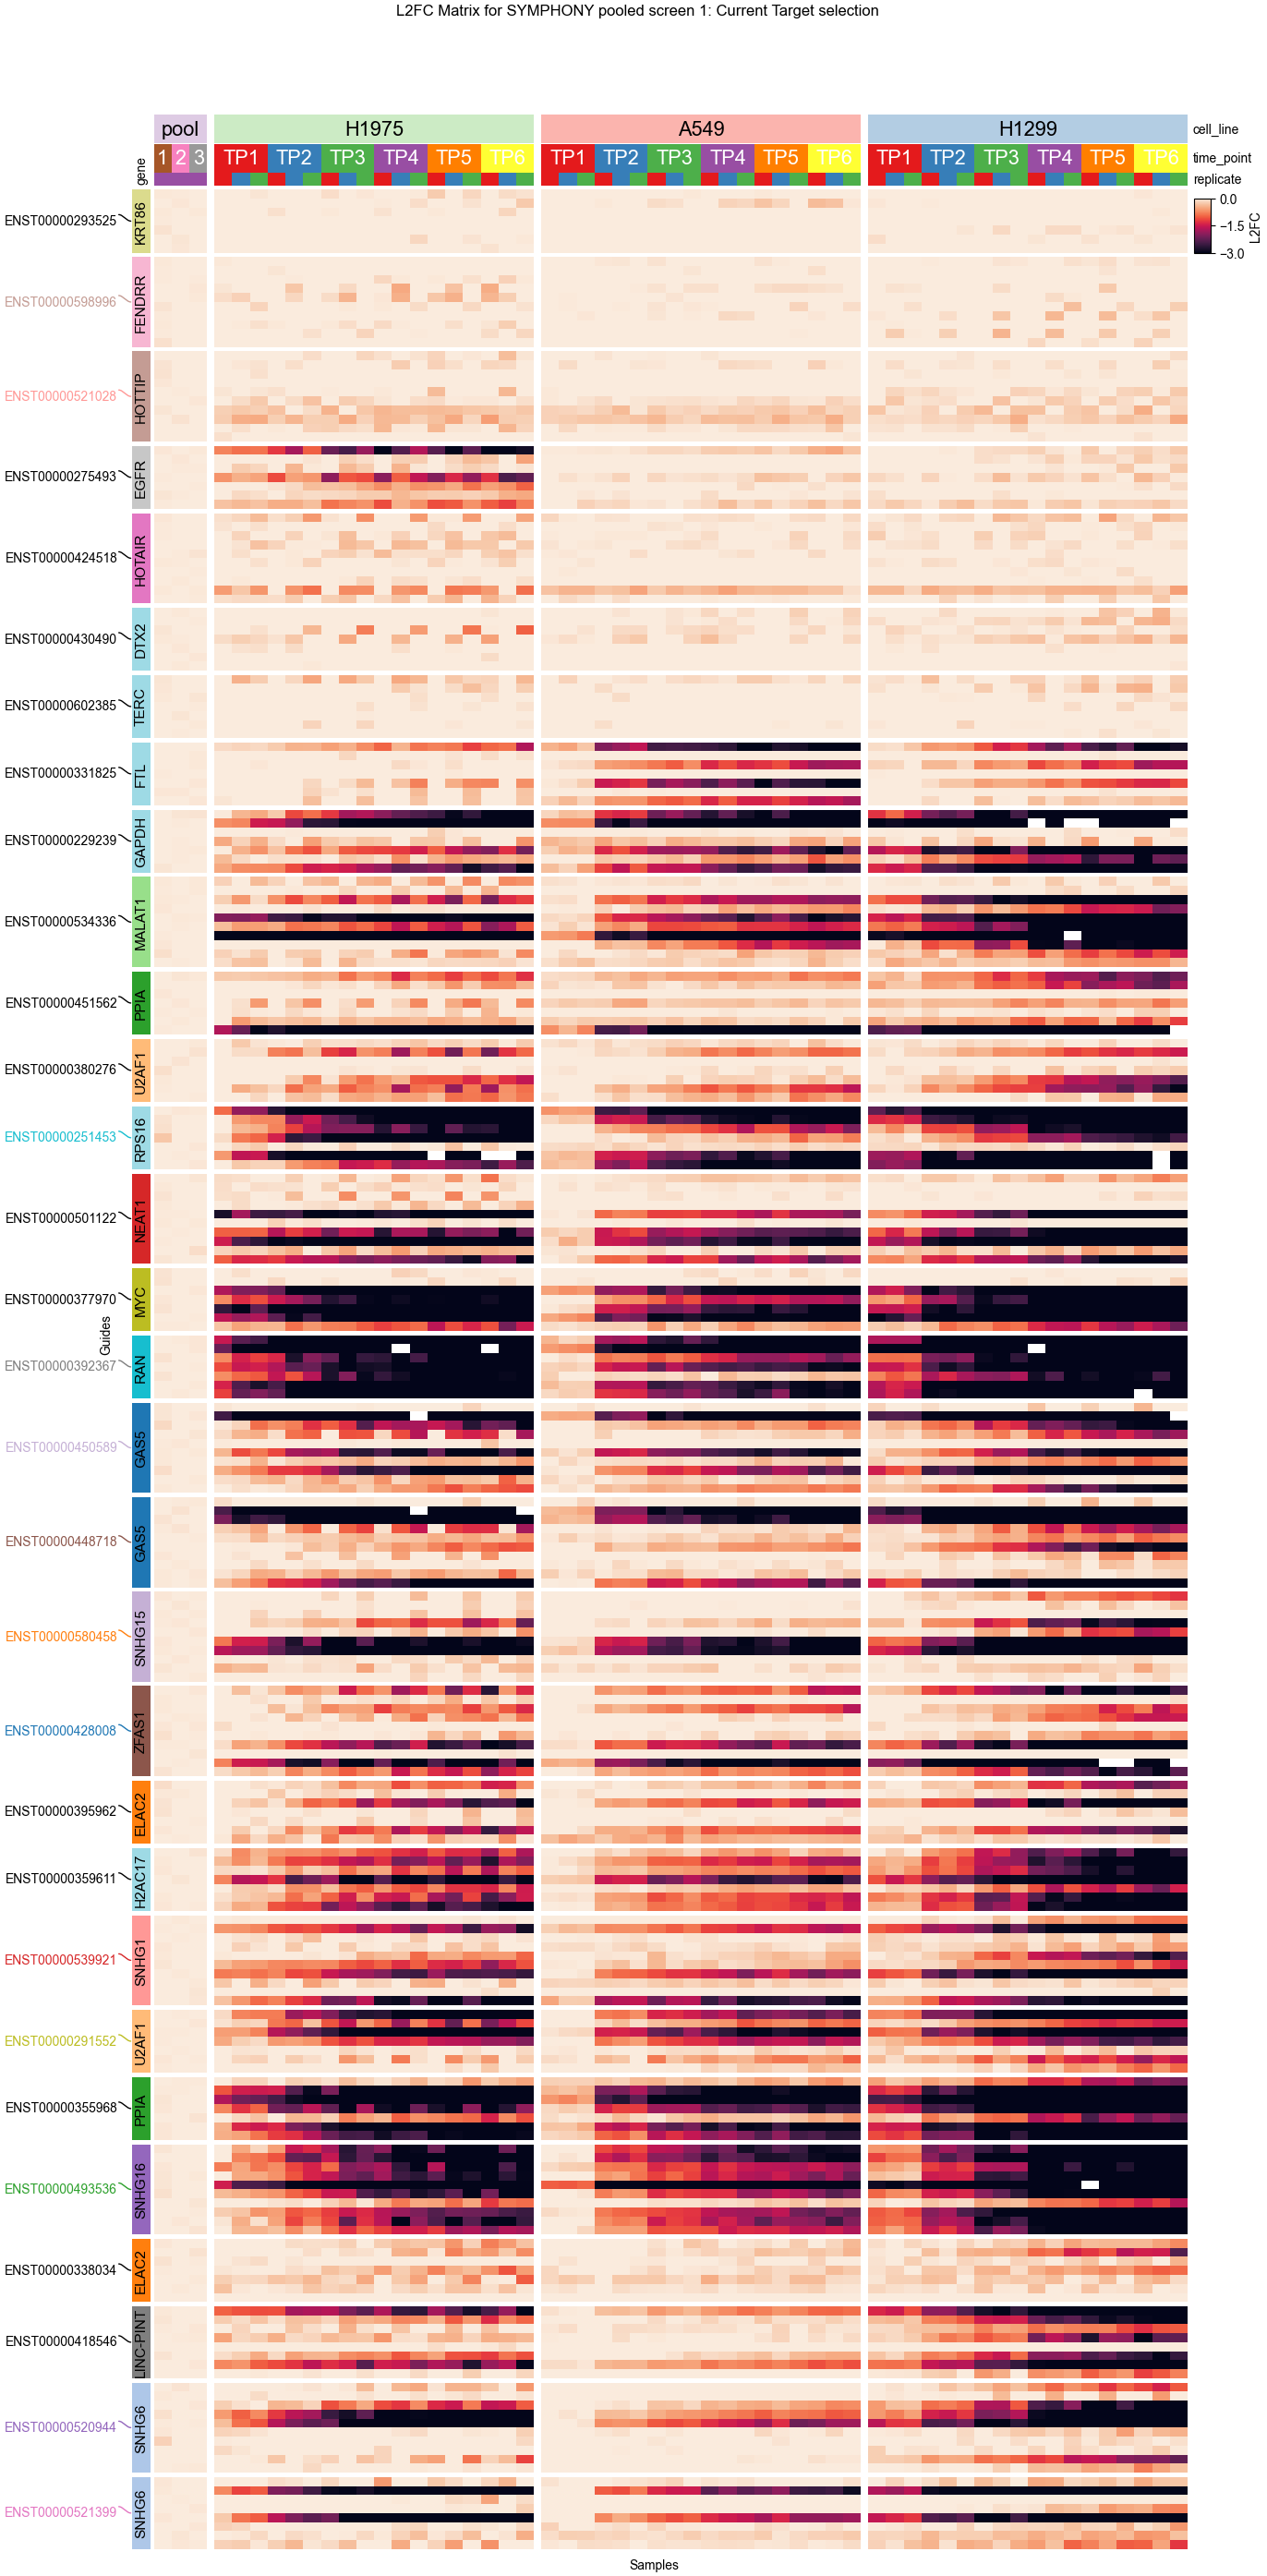

In [10]:
# visualize in heatmap CUSTOM GUIDES
df = pd.read_csv(TEMPDIR / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

# First I normalize for seq-depth by bringing all NT guides to the same count
target = df.loc[controls, sample_names_wo_pools].mean().mean()  # mean of NTs in control
ist = df.loc[controls, sample_names].mean()  # mean of NTs in all
norm_factor = target / ist  # make all NT mean counts equal to those in control
ndf = df.loc[:, sample_names] * norm_factor  # normalize

# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T  # normalize to control (pools)
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

import PyComplexHeatmap as pch
df['mean_l2fc'] = l2fc.mean(axis=1)

df = df[df.index.isin(selection)]
l2fc = l2fc.loc[df.index]

biotype = df.sort_values(['Gene', 'transcript_biotype', 'mean_l2fc']).transcript_biotype
biotype = biotype[~biotype.isin(['protein_coding_CDS_not_defined', 'retained_intron'])]

cell_line_dict_ = {f'0{x}': y for x, y in cell_line_dict.items()}
cell_line = pd.Series({x: x.split('-')[1] for x in sample_names}).replace(cell_line_dict_)
replicate = pd.Series({x: x.split('-')[2] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in sample_names})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

# select and reorder
data = l2fc.loc[:, col_order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=7, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df.Transcript_ID, merge=True, cmap='tab20'),
    gene=pch.anno_simple(df.Gene, legend=False, height=5, add_text=True, cmap='tab20'),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(15, 30))
cm = pch.ClusterMapPlotter(
    data=data, 
    left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    col_split=cell_line.loc[col_order],
    col_split_gap=2, row_split_gap=1,
    row_split=df.Transcript_ID,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=-3, vmax=0,
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Guides', legend_hpad=0,
    verbose=0
)
pl.suptitle('L2FC Matrix for SYMPHONY pooled screen 1: Current Target selection', y=0.92)
pl.savefig('../results/figures/count_matrix_l2fc_heatmap_simple_3.png', dpi=300)
pl.savefig('../results/figures/count_matrix_l2fc_heatmap_simple_3.pdf', dpi=300)
pl.show()

# Detection using BAGEL

In [ ]:
# Use results from BAGEL2 to detect cell line specific essential genes
bagel = pd.read_table('../results/tables/pooled_screen_1_counts_bagel_pr_gene.tsv', index_col=0, header=[0,1,2])
sdf = bagel.xs('BF', level=2, axis=1).xs('alltimes', level=1, axis=1)

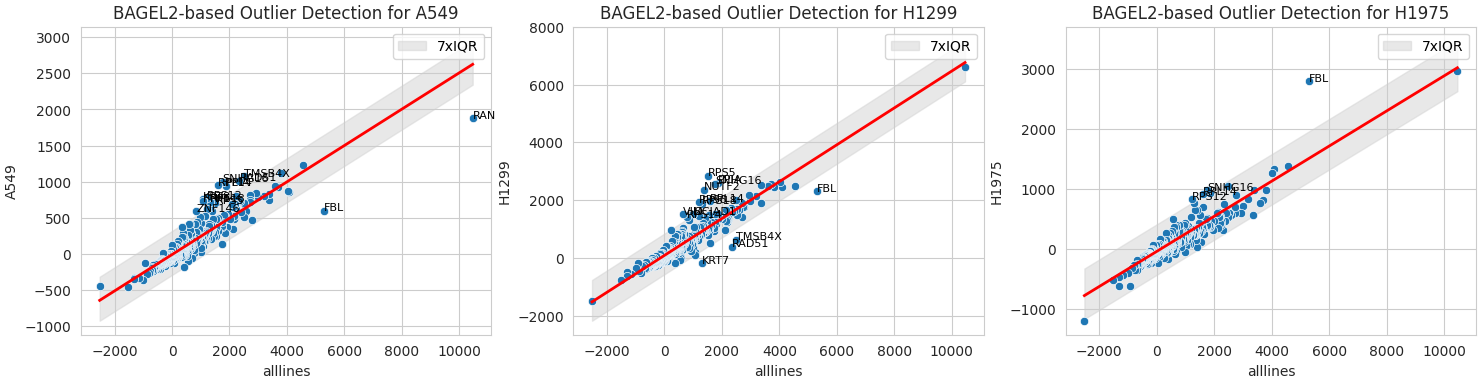

In [ ]:
from sklearn import linear_model

outlier_genes_up = {}
outlier_genes_down = {}
with sns.axes_style('whitegrid'):
    fig, axs = pl.subplots(1, 3, figsize=(6 * 3,4))

for ax, line in zip(axs, ['A549', 'H1299', 'H1975']):
    xkey = 'alllines'
    ykey = line

    # Data #
    x, y = sdf[xkey].values.reshape(-1, 1), sdf[ykey].values.reshape(-1, 1)
    # Make fit #
    regr = linear_model.LinearRegression()
    regr.fit(x, y)
    y_pred = regr.predict(x)

    # Detect outliers #
    residuals = y - y_pred
    IQR = np.percentile(residuals, 75) - np.percentile(residuals, 25)
    Q1 = np.percentile(residuals, 25)
    Q3 = np.percentile(residuals, 75)
    factor = 7 # width of the IQR zone for outlier detection
    mask_up = np.ravel(((residuals > Q3 + factor*IQR)) & (y_pred > 0))
    mask_down = np.ravel(((residuals < Q1 - factor*IQR)) & (y_pred > 0))
    mask = mask_up | mask_down
    outlier_genes_up[line] = sdf.index[mask_up].tolist()
    outlier_genes_down[line] = sdf.index[mask_down].tolist()

    # Plot #
    sns.scatterplot(data=sdf, x=xkey, y=ykey, ax=ax)
    ax.plot(x, y_pred, color='red', linewidth=2)
    for i, txt in enumerate(sdf.index[mask]):
        ax.annotate(txt, (x[mask][i], y[mask][i]), fontsize=8)
    ax.fill_between(np.ravel(x), np.ravel(y_pred - Q1 - factor*IQR), np.ravel(y_pred + Q3 + factor*IQR), 
                    color='lightgray', alpha=0.5, zorder=-1, label=f'{factor}xIQR')
    ax.set_title(f'BAGEL2-based Outlier Detection for {line}')
    ax.legend()
pl.show()

In [ ]:
# this is a dict of lists of genes that are outliers in the respective cell lines
# make it a dataframe where index is gene and columns are cell lines
index = list(set(outlier_genes_up['A549'] + outlier_genes_up['H1299'] + outlier_genes_up['H1975'] + \
                 outlier_genes_down['A549'] + outlier_genes_down['H1299'] + outlier_genes_down['H1975']
                 ))
outlier_df = pd.DataFrame(0, index=index, columns=['A549', 'H1299', 'H1975'])
for line in ['A549', 'H1299', 'H1975']:
    outlier_df.loc[outlier_genes_up[line], line] = 1
    outlier_df.loc[outlier_genes_down[line], line] = -1
# outlier_df is per gene; make per guide
# is_outlier_guide = pd.DataFrame({guide: outlier_df.loc[gene] for guide, gene in zip(df.index, df.Gene) if gene in outlier_df.index}).T.astype(str)
is_outlier_guide = pd.DataFrame({guide: outlier_df.loc[gene] for guide, gene in zip(df.index, df.Gene) if gene in outlier_df.index}).T

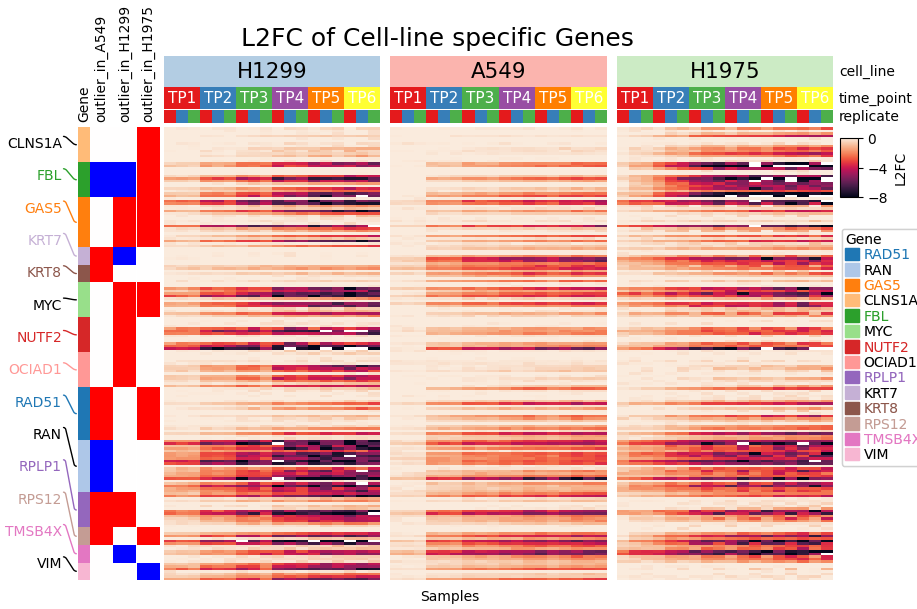

In [ ]:
# correlation between samples
data = l2fc.loc[df.Gene.isin(index), sample_names_wo_pools].sort_index()

cell_line = pd.Series({x: int(x.split('-')[1]) for x in data.columns}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2] for x in data.columns})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in data.columns})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

data = data.loc[:, col_order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=5, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

kwargs = dict(height=6, cmap='bwr', legend=False)
left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df.loc[data.index, 'Gene'], merge=True, extend=True),
    Gene=pch.anno_simple(df.loc[data.index, 'Gene']),
    outlier_in_A549=pch.anno_simple(is_outlier_guide['A549'], **kwargs),
    outlier_in_H1299=pch.anno_simple(is_outlier_guide['H1299'], **kwargs),
    outlier_in_H1975=pch.anno_simple(is_outlier_guide['H1975'], **kwargs),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(10, 6))
cm = pch.ClusterMapPlotter(
    data=data, top_annotation=top_ha, left_annotation=left_ha,
    row_cluster=False, col_cluster=False,
    legend_gap=7, vmax=0, vmin=-8,
    col_split=cell_line.loc[col_order], col_split_gap=2.5,
    rasterized=True, cmap='rocket',
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='', legend_hpad=0,
    verbose=0
)
pl.suptitle("L2FC of Cell-line specific Genes", y=0.93, fontsize=18)
pl.show()

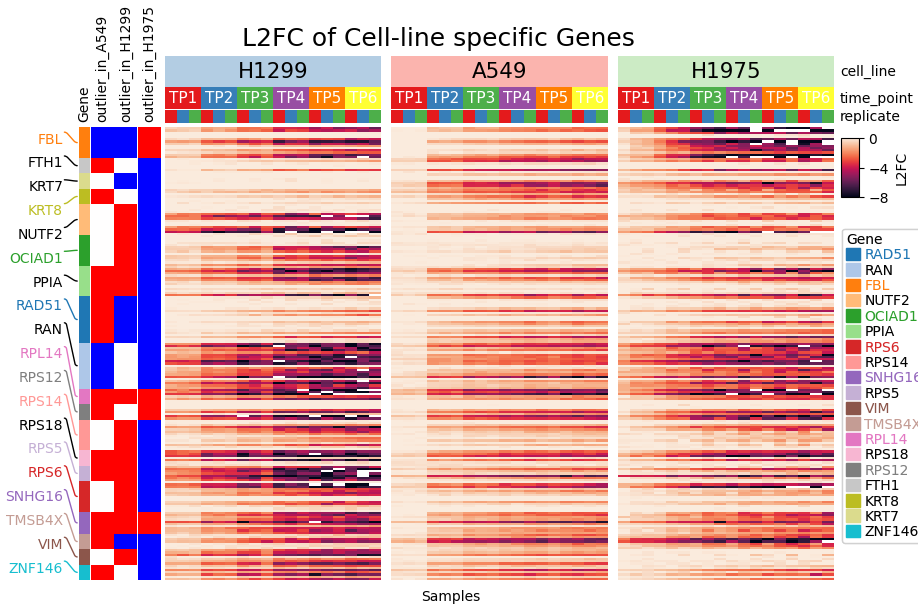

In [ ]:
# correlation between samples
data = l2fc.loc[df.Gene.isin(index), sample_names_wo_pools].sort_index()

cell_line = pd.Series({x: int(x.split('-')[1]) for x in data.columns}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2] for x in data.columns})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in data.columns})
col_order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 2, 1]).index  # sort by time before replicate

data = data.loc[:, col_order]

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line.loc[col_order], add_text=True, height=7, cmap='Pastel1'),
    time_point=pch.anno_simple(time_point.loc[col_order], add_text=True, height=5, cmap='Set1'),
    replicate=pch.anno_simple(replicate.loc[col_order], add_text=False),
    verbose=0, axis=1, plot_legend=False
)

kwargs = dict(height=6, cmap='bwr', legend=False)
left_ha = pch.HeatmapAnnotation(
    label=pch.anno_label(df.loc[data.index, 'Gene'], merge=True, extend=True),
    Gene=pch.anno_simple(df.loc[data.index, 'Gene']),
    outlier_in_A549=pch.anno_simple(is_outlier_guide['A549'], **kwargs),
    outlier_in_H1299=pch.anno_simple(is_outlier_guide['H1299'], **kwargs),
    outlier_in_H1975=pch.anno_simple(is_outlier_guide['H1975'], **kwargs),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(10, 6))
cm = pch.ClusterMapPlotter(
    data=data, top_annotation=top_ha, left_annotation=left_ha,
    row_cluster=False, col_cluster=False,
    legend_gap=7, vmax=0, vmin=-8,
    col_split=cell_line.loc[col_order], col_split_gap=2.5,
    rasterized=True, cmap='rocket',
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='', legend_hpad=0,
    verbose=0
)
pl.suptitle("L2FC of Cell-line specific Genes", y=0.93, fontsize=18)
pl.show()